# 🎙️ TimeXer‑DINOv3 — Quy trình thu thập & xử lý dữ liệu giọng nói → nhóm tuổi

Notebook này trình bày **toàn bộ luồng dữ liệu** của dự án *Dự đoán độ tuổi từ giọng nói bằng TimeXer (encoder DINOv3)*,
bám đúng sơ đồ thiết kế:

```
Thiết bị vật lý ──Thu thập──▶ Truyền dữ liệu ──▶ Lưu trữ (máy chủ)
 (điện thoại / laptop / tai nghe)                    data/raw/<source>/<clip_id>.wav + .json
      ▼
Tiền xử lý:  khử nhiễu (spectral gating) → cắt im lặng & chuẩn hoá độ dài 5 s → chuẩn hoá biên độ
      ▼
Trích xuất đặc trưng:  log‑Mel · MFCC · Pitch (F0) · Formant (F1–F3) · Energy · ZCR · Spectral centroid
      ▼
Xây dựng biến đầu vào TimeXer:  y ∈ R^(T×d_y) nội sinh (log‑Mel 128×251)  ·  x ∈ R^(T×d_x) ngoại sinh (13×251: thời gian ghi, ngữ cảnh ghi âm, tín hiệu hỗ trợ)
      ▼
Chia train/val/test theo NGƯỜI NÓI (speaker‑disjoint) ──▶ Huấn luyện TimeXer‑DINOv3 ──▶ Đánh giá ──▶ Thông báo kết quả (UI)
```

Mỗi bước dưới đây đều chạy **code thật** của pipeline (`code/src/data/audio_processing.py`, `code/scripts/01…03`) trên dữ liệu
trong dataset đính kèm — không phải mô tả suông.

| Bước | Code | Đầu ra trong dataset |
|---|---|---|
| 1. Thu thập (seed có nhãn + private) | `scripts/01_seed_common_voice.py`, app `/collect` + `scripts/02_ingest_private.py` | `raw_manifest.csv` |
| 2. Tiền xử lý | `audio_processing.preprocess_waveform` | `audio_16k_flac/` |
| 3. Đặc trưng y / x | `audio_processing.extract_features` | `mel_logspec.npy`, `exog_series.npy`, `features_scalar.csv` |
| 4. Chia dữ liệu | `scripts/03_build_dataset.py::speaker_split` | `metadata.csv` (cột `split`) |


In [1]:
import os, sys, json, subprocess
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# ---- vị trí dataset: Kaggle (/kaggle/input/...) hoặc local (KAGGLE_INPUT_DIR) ----
CANDS = [Path(os.environ.get('KAGGLE_INPUT_DIR', 'data/kaggle_dataset')), Path('/kaggle/input/voice-age-timexer-dinov3-vi')]
if Path('/kaggle/input').exists():
    CANDS += sorted(Path('/kaggle/input').glob('*'))
INPUT = next((p for p in CANDS if (p / 'dataset_manifest.json').exists()), None)
assert INPUT is not None, 'Không tìm thấy dataset. Trên Kaggle: Add Data -> voice-age-timexer-dinov3-vi'
WORK = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('kaggle_working'); WORK.mkdir(exist_ok=True)
print('INPUT =', INPUT); print('WORK  =', WORK)

# ---- thư viện xử lý âm thanh (Kaggle đã có librosa/soundfile) ----
# noisereduce chỉ dùng để minh hoạ khử nhiễu; nếu không cài được (Internet tắt / DNS lỗi)
# thì audio_processing.denoise() tự bỏ qua và giữ nguyên waveform.
try:
    import noisereduce  # noqa
    print('noisereduce: OK')
except ImportError:
    print('noisereduce: không có — bước khử nhiễu sẽ được bỏ qua (không làm hỏng pipeline)')
import librosa, soundfile as sf

# ---- import code pipeline đi kèm dataset ----
sys.path.insert(0, str(INPUT / 'code'))
from src.common.constants import (AGE_GROUPS, COMMON_VOICE_AGE_MAP, SAMPLE_RATE, CLIP_SECONDS, N_MELS, N_FFT, HOP_LENGTH,
                                  EXOG_COLS, EXOG_STATIC_COLS, EXOG_FRAME_COLS, PROSODY_COLS, age_years_to_group)
from src.data import audio_processing as ap
from src.data.audio_processing import N_FRAMES
print('Nhóm tuổi:', AGE_GROUPS)
print(f'Audio: {SAMPLE_RATE} Hz · clip {CLIP_SECONDS} s · log-Mel {N_MELS}×{N_FRAMES} (n_fft {N_FFT}, hop {HOP_LENGTH})')

INPUT = C:\TailieucuaSang\Time-series\timexer-dinov3-voice-age\data\kaggle_dataset
WORK  = kaggle_working


C:\Users\ThinkPad\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Nhóm tuổi: ['<18', '18-29', '30-49', '50-64', '65+']
Audio: 16000 Hz · clip 5.0 s · log-Mel 128×251 (n_fft 1024, hop 320)


## 1. Thu thập dữ liệu

### 1a. Thiết bị vật lý → Thu thập → Truyền → Lưu trữ (dữ liệu *private*)

Người dùng ghi âm trên **điện thoại / laptop / tai nghe** qua trang `/collect` của hệ thống (HTML + Web Audio API).
Trình duyệt giải mã về WAV 16 kHz rồi `POST /api/collect` kèm metadata; máy chủ lưu `data/raw/private/<clip_id>.wav` + `<clip_id>.json`:

```json
{
  "clip_id": "20261018_203635_80892b",
  "recorded_at": "2026-10-18T20:36:35+07:00",     // thời điểm ghi THẬT -> biến ngoại sinh hour/dow
  "age": 24, "age_group": "18-29", "gender": "male",
  "device": "phone", "environment": "quiet", "source_mic": true,
  "locale": "vi", "consent": true, "user_agent": "Mozilla/5.0 (Linux; Android ...)"
}
```

`scripts/02_ingest_private.py` quét thư mục này và hợp nhất vào `raw_manifest.csv` theo **cùng schema** với dữ liệu seed.

### 1b. Seed có nhãn tuổi (Common Voice 17, CC0)

Dữ liệu private thu tay ban đầu còn ít, nên pipeline khởi động bằng clip **có nhãn tuổi** của Mozilla Common Voice 17
(`scripts/01_seed_common_voice.py`, đọc parquet từ mirror `fixie-ai/common_voice_17_0`): toàn bộ tiếng Việt + tiếng Anh cho
**mọi** nhóm tuổi với giới hạn số clip/nhóm (tránh mô hình học "ngôn ngữ = tuổi"). Nhãn thập niên → 5 nhóm:

In [2]:
pd.Series(COMMON_VOICE_AGE_MAP).rename('age_group').to_frame().T

,teens,twenties,thirties,fourties,fifties,sixties,seventies,eighties,nineties
age_group,<18,18-29,30-49,30-49,50-64,50-64,65+,65+,65+


### 1c. Đầu ra bước Thu thập: `raw_manifest.csv`

Mỗi dòng = một bản ghi gốc (trước tiền xử lý) với nguồn, người nói, nhãn tuổi, giới tính, ngôn ngữ, thời điểm/thiết bị/môi trường ghi.

(8469, 12)


,clip_id,source,speaker_id,age_group,age_raw,gender,locale,recorded_at,device,environment,sentence
0,cvvi_common_voice_vi_26136615,common_voice_17_vi,2f5a7eadfd319fc2c8d0ffba,30-49,thirties,male,vi,NaN,unknown,unknown,Ngày em đi cất nhẹ gót quay về
1,cvvi_common_voice_vi_30646474,common_voice_17_vi,4e59f9ea20c5426b330c3024,18-29,twenties,male,vi,NaN,unknown,unknown,mẹ lại cầm tay của em lẩm bẩm
2,cvvi_common_voice_vi_25157829,common_voice_17_vi,790bfccf475d84e50a09b0ba,30-49,thirties,male,vi,NaN,unknown,unknown,Ra đến chỗ để xe thì Phương chép miệng
3,cvvi_common_voice_vi_27670258,common_voice_17_vi,7e03cd4d9515bd03c835e9ff,18-29,twenties,male,vi,NaN,unknown,unknown,"Tháng mười rồi, đêm sẽ bỗng dài hơn?"
4,cvvi_common_voice_vi_31437120,common_voice_17_vi,8eeb30c3eea2723c335e5ef5,18-29,twenties,male,vi,NaN,unknown,unknown,Từng chút từng chút một
5,cvvi_common_voice_vi_30946618,common_voice_17_vi,af16eb19adce58ff9e7b2de6,30-49,thirties,male,vi,NaN,unknown,unknown,Vợ tôi cũng bị một chiếc xe như vậy
6,cvvi_common_voice_vi_23891882,common_voice_17_vi,244e585593b49da99068ed3d,18-29,twenties,male,vi,NaN,unknown,unknown,Con của tao Ngoan hiền lắm dễ thương biết nghe...
7,cvvi_common_voice_vi_23891886,common_voice_17_vi,244e585593b49da99068ed3d,18-29,twenties,male,vi,NaN,unknown,unknown,Mày lại mơ à


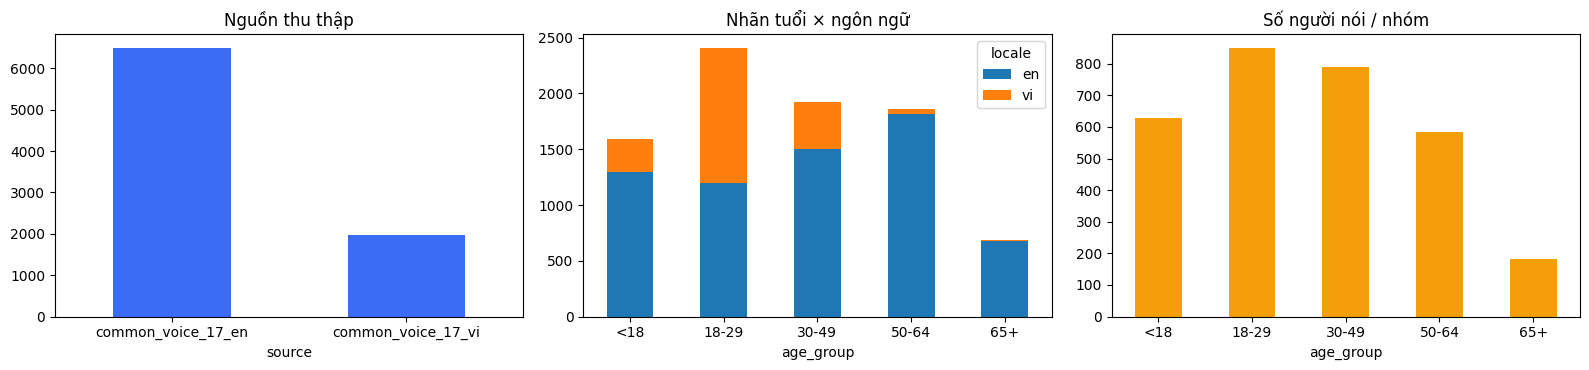

Thiết bị/môi trường (private có giá trị thật, seed = unknown):
device   environment
unknown  unknown        8469
Name: count, dtype: int64


In [3]:
raw = pd.read_csv(INPUT / 'raw_manifest.csv')
print(raw.shape); display(raw.drop(columns=['path']).head(8))
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
raw.source.value_counts().plot.bar(ax=ax[0], rot=0, title='Nguồn thu thập', color='#3b6cf5')
pd.crosstab(raw.age_group, raw.locale).reindex(AGE_GROUPS).plot.bar(stacked=True, ax=ax[1], rot=0, title='Nhãn tuổi × ngôn ngữ')
raw.groupby('age_group').speaker_id.nunique().reindex(AGE_GROUPS).plot.bar(ax=ax[2], rot=0, color='#f59e0b', title='Số người nói / nhóm')
plt.tight_layout(); plt.show()
print('Thiết bị/môi trường (private có giá trị thật, seed = unknown):'); print(raw[['device','environment']].value_counts().head())

## 2. Tiền xử lý — chạy từng bước trên một clip thật

`preprocess_waveform` = **khử nhiễu** (spectral gating, `noisereduce`) → **cắt im lặng đầu/cuối & chuẩn hoá về đúng 5 s** (crop giữa hoặc pad) → **chuẩn hoá biên độ** (peak 0.95).
Dataset chỉ chứa audio *sau* bước này, nên để minh hoạ ta tạo lại một "bản ghi thô" bằng cách thêm nhiễu nền + im lặng vào clip, rồi chạy pipeline.

cven_common_voice_en_100460.flac | nhóm tuổi: 18-29 | giới tính: male | locale: en


stats: {'raw_duration_s': 7.0, 'speech_duration_s': 2.94}


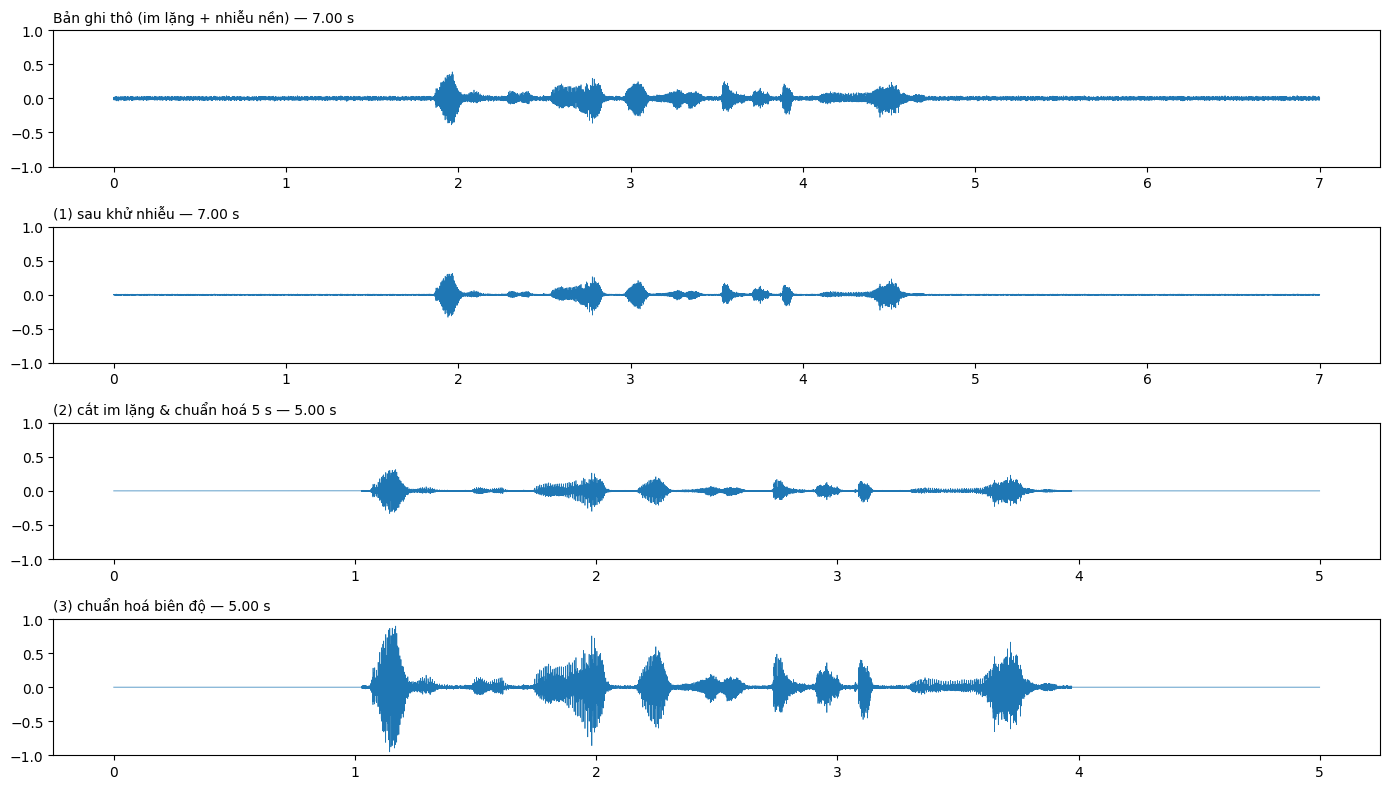

Nghe thử: thô vs sau tiền xử lý


In [4]:
flacs = sorted((INPUT / 'audio_16k_flac').glob('*.flac'))
meta_all = pd.read_csv(INPUT / 'metadata.csv').set_index('clip_id')
clip = flacs[0]; info = meta_all.loc[clip.stem]
print(clip.name, '| nhóm tuổi:', info.age_group, '| giới tính:', info.gender, '| locale:', info.locale)

y_clean, orig_sr = ap.load_audio(str(clip))                       # bước 0: đọc file bất kỳ -> mono float32 16 kHz
rng = np.random.default_rng(0)
y_raw = np.concatenate([np.zeros(int(0.8 * SAMPLE_RATE)), y_clean, np.zeros(int(1.2 * SAMPLE_RATE))]).astype(np.float32)
y_raw = y_raw * 0.4 + rng.normal(0, 0.01, len(y_raw)).astype(np.float32)   # giả lập mic nhỏ + nhiễu nền

y_dn = ap.denoise(y_raw, SAMPLE_RATE)                             # (1) khử nhiễu
y_tr, speech_dur = ap.trim_and_fix_length(y_dn, SAMPLE_RATE)      # (2) cắt im lặng + chuẩn hoá 5 s
y_pp = ap.normalize_amplitude(y_tr)                               # (3) chuẩn hoá biên độ
y_pp2, stats = ap.preprocess_waveform(y_raw, SAMPLE_RATE)         # cùng kết quả qua hàm gộp
assert np.allclose(y_pp, y_pp2, atol=1e-6); print('stats:', {k: round(v, 2) for k, v in stats.items()})

fig, ax = plt.subplots(4, 1, figsize=(14, 8), sharex=False)
for a, (sig, t) in zip(ax, [(y_raw, 'Bản ghi thô (im lặng + nhiễu nền)'), (y_dn, '(1) sau khử nhiễu'), (y_tr, '(2) cắt im lặng & chuẩn hoá 5 s'), (y_pp, '(3) chuẩn hoá biên độ')]):
    a.plot(np.arange(len(sig)) / SAMPLE_RATE, sig, lw=0.5); a.set_title(f'{t} — {len(sig)/SAMPLE_RATE:.2f} s', loc='left', fontsize=10); a.set_ylim(-1, 1)
plt.tight_layout(); plt.show()
from IPython.display import Audio, display
print('Nghe thử: thô vs sau tiền xử lý'); display(Audio(y_raw, rate=SAMPLE_RATE)); display(Audio(y_pp, rate=SAMPLE_RATE))

## 3. Trích xuất đặc trưng → biến đầu vào TimeXer

| Biến | Nội dung | Kích thước |
|---|---|---|
| **y** nội sinh | log‑Mel spectrogram (dB) — đầu vào của encoder DINOv3 | `[128, 251]` |
| prosody (nội sinh, mức clip) | MFCC‑20 mean/std, F0 mean/std/median, voiced ratio, formant F1–F3, energy, ZCR, centroid | 51 số |
| **x** ngoại sinh | 9 kênh tĩnh (hour/dow sin‑cos, thời lượng, SNR, RMS, mic/upload, sample‑rate gốc) + 4 chuỗi theo khung (F0, energy, ZCR, centroid) | `[13, 251]` |

y log-Mel : (128, 251) float16
x exog    : (13, 251) | cột: ['hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'duration_norm', 'snr_db_norm', 'rms_db_norm', 'source_mic', 'orig_sr_norm', 'f0_contour', 'energy_contour', 'zcr_contour', 'centroid_contour']
prosody   : 51 đặc trưng  (vd. F0 mean = 213.0 Hz, F1 = 796 Hz, F2 = 1579 Hz)


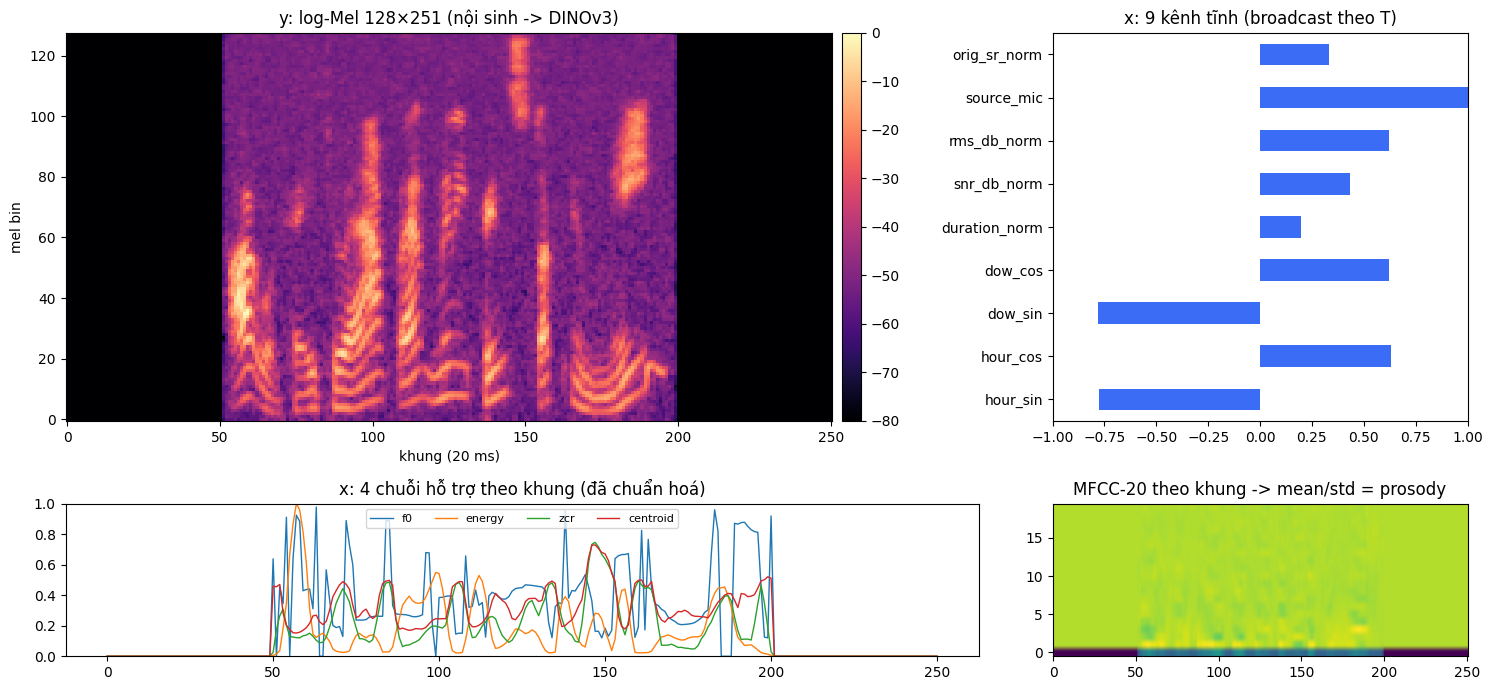

In [5]:
from datetime import datetime
rec_at = datetime(2026, 10, 18, 20, 36)   # thời điểm ghi (dữ liệu private); seed Common Voice -> None (hour/dow = 0)
feats = ap.extract_features(y_pp, SAMPLE_RATE, recorded_at=rec_at, source_mic=True, orig_sr=orig_sr, speech_duration_s=stats['speech_duration_s'])
print('y log-Mel :', feats.log_mel.shape, feats.log_mel.dtype)
print('x exog    :', feats.exog.shape, '| cột:', EXOG_COLS)
print('prosody   :', len(PROSODY_COLS), 'đặc trưng  (vd. F0 mean = %.1f Hz, F1 = %.0f Hz, F2 = %.0f Hz)' % (feats.scalars['f0_mean'], feats.scalars['formant_f1'], feats.scalars['formant_f2']))

fig = plt.figure(figsize=(15, 7)); gs = fig.add_gridspec(3, 2, width_ratios=[2.2, 1])
ax0 = fig.add_subplot(gs[0:2, 0]); im = ax0.imshow(feats.log_mel.astype(np.float32), origin='lower', aspect='auto', cmap='magma'); ax0.set_title('y: log-Mel 128×251 (nội sinh -> DINOv3)'); ax0.set_xlabel('khung (20 ms)'); ax0.set_ylabel('mel bin'); plt.colorbar(im, ax=ax0, pad=0.01)
ax1 = fig.add_subplot(gs[2, 0]); ex = feats.exog.astype(np.float32)
for c in EXOG_FRAME_COLS: ax1.plot(ex[EXOG_COLS.index(c)], lw=1, label=c.replace('_contour', ''))
ax1.set_title('x: 4 chuỗi hỗ trợ theo khung (đã chuẩn hoá)'); ax1.legend(ncol=4, fontsize=8); ax1.set_ylim(0, 1)
ax2 = fig.add_subplot(gs[0:2, 1]); static = pd.Series({c: ex[EXOG_COLS.index(c), 0] for c in EXOG_STATIC_COLS}); static.plot.barh(ax=ax2, color='#3b6cf5'); ax2.set_title('x: 9 kênh tĩnh (broadcast theo T)'); ax2.set_xlim(-1, 1)
ax3 = fig.add_subplot(gs[2, 1]); mf = ap.mfcc_features(feats.log_mel.astype(np.float32)); ax3.imshow(mf, aspect='auto', origin='lower', cmap='viridis'); ax3.set_title('MFCC-20 theo khung -> mean/std = prosody')
plt.tight_layout(); plt.show()

### 3b. Pitch & formant — đặc trưng mang thông tin tuổi
F0 (YIN) và formant (LPC) là hai đặc trưng kinh điển: F0 giảm theo tuổi ở nữ, formant dịch theo kích thước ống thanh.

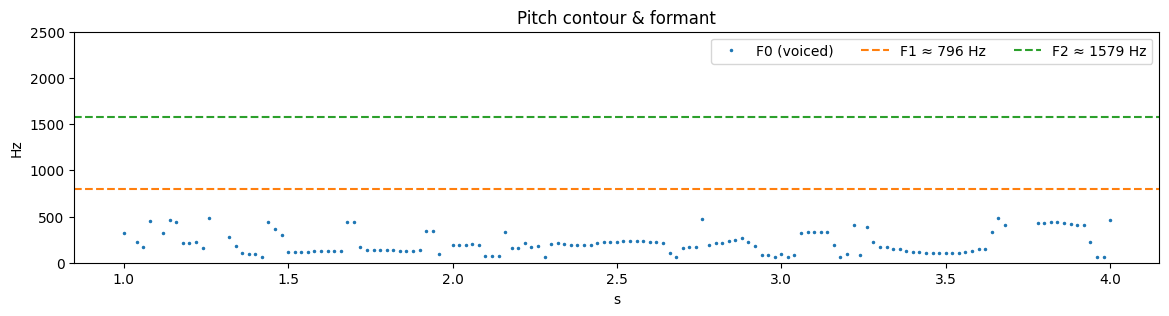

In [6]:
f0, voiced = ap.pitch_contour(y_pp, SAMPLE_RATE); f1, f2, f3 = ap.formant_estimates(y_pp, SAMPLE_RATE)
t = np.arange(len(f0)) * HOP_LENGTH / SAMPLE_RATE
plt.figure(figsize=(14, 3)); plt.plot(t, np.where(voiced, f0, np.nan), '.', ms=3, label='F0 (voiced)'); plt.axhline(f1, color='C1', ls='--', label=f'F1 ≈ {f1:.0f} Hz'); plt.axhline(f2, color='C2', ls='--', label=f'F2 ≈ {f2:.0f} Hz')
plt.ylim(0, 2500); plt.xlabel('s'); plt.ylabel('Hz'); plt.title('Pitch contour & formant'); plt.legend(ncol=3); plt.show()

### 3c. Hàm end‑to‑end dùng chung cho **xây dựng dataset** và **suy luận trên server**
`process_clip(file|bytes, recorded_at, source_mic)` gói trọn: đọc → tiền xử lý → đặc trưng. Backend FastAPI gọi đúng hàm này,
nên dữ liệu train và dữ liệu lúc dự đoán được xử lý **y hệt nhau** (không lệch phân phối).

In [7]:
y5, F = ap.process_clip(str(flacs[1]), recorded_at=None, source_mic=False)
print(flacs[1].name, '->', 'y', F.log_mel.shape, '| x', F.exog.shape, '| scalars:', {k: round(float(v), 3) for k, v in list(F.scalars.items())[:8]}, '...')

cven_common_voice_en_101002.flac -> y (128, 251) | x (13, 251) | scalars: {'hour_sin': 0.0, 'hour_cos': 0.0, 'dow_sin': 0.0, 'dow_cos': 0.0, 'duration_norm': 0.245, 'snr_db_norm': 0.812, 'rms_db_norm': 0.602, 'source_mic': 0.0} ...


## 4. Xây dựng toàn bộ dataset & chia theo người nói

`scripts/03_build_dataset.py` chạy `process_clip` song song (multiprocessing) trên mọi dòng của `raw_manifest.csv`, ghi:
`mel_logspec.npy [N,128,251]`, `exog_series.npy [N,13,251]`, `features_scalar.csv`, `metadata.csv` (+ `audio_16k/`).

Split **speaker‑disjoint**: một người nói chỉ xuất hiện trong đúng một tập; phân tầng xấp xỉ theo nhóm tuổi chủ đạo của người nói
(`speaker_split`). Dưới đây chạy lại chính hàm đó và kiểm chứng.

In [8]:
import importlib.util
spec = importlib.util.spec_from_file_location('build_ds', INPUT / 'code' / 'scripts' / '03_build_dataset.py'); build_ds = importlib.util.module_from_spec(spec); spec.loader.exec_module(build_ds)
meta = pd.read_csv(INPUT / 'metadata.csv')
split_again = build_ds.speaker_split(meta, val_frac=0.15, test_frac=0.15, seed=42)
print('Khớp với split đã lưu:', (split_again == meta.split).mean().round(4))
spk_sets = {s: set(meta.loc[meta.split == s, 'speaker_id']) for s in ['train', 'val', 'test']}
print('Speaker trùng train∩test:', len(spk_sets['train'] & spk_sets['test']), '| train∩val:', len(spk_sets['train'] & spk_sets['val']))
display(pd.crosstab(meta.age_group, meta.split).reindex(AGE_GROUPS)[['train', 'val', 'test']])

Khớp với split đã lưu: 1.0
Speaker trùng train∩test: 0 | train∩val: 0


split,train,val,test
age_group,,,
<18,1167,202,225
18-29,1723,309,377
30-49,1368,262,294
50-64,1395,159,303
65+,531,98,56


### 4b. Kiểm tra sản phẩm cuối của pipeline (những gì mô hình đọc)

{
 "n_clips": 8469,
 "n_speakers": 3028,
 "label_counts": {
  "<18": 1594,
  "18-29": 2409,
  "30-49": 1924,
  "50-64": 1857,
  "65+": 685
 },
 "split_counts": {
  "train": 6184,
  "test": 1255,
  "val": 1030
 },
 "sources": {
  "common_voice_17_en": 6492,
  "common_voice_17_vi": 1977
 },
 "split_strategy": "speaker-disjoint, stratified by speaker's dominant age group"
}
mel_logspec.npy (8469, 128, 251) float16 | exog_series.npy (8469, 13, 251) float16 | features_scalar.csv (8469, 66)


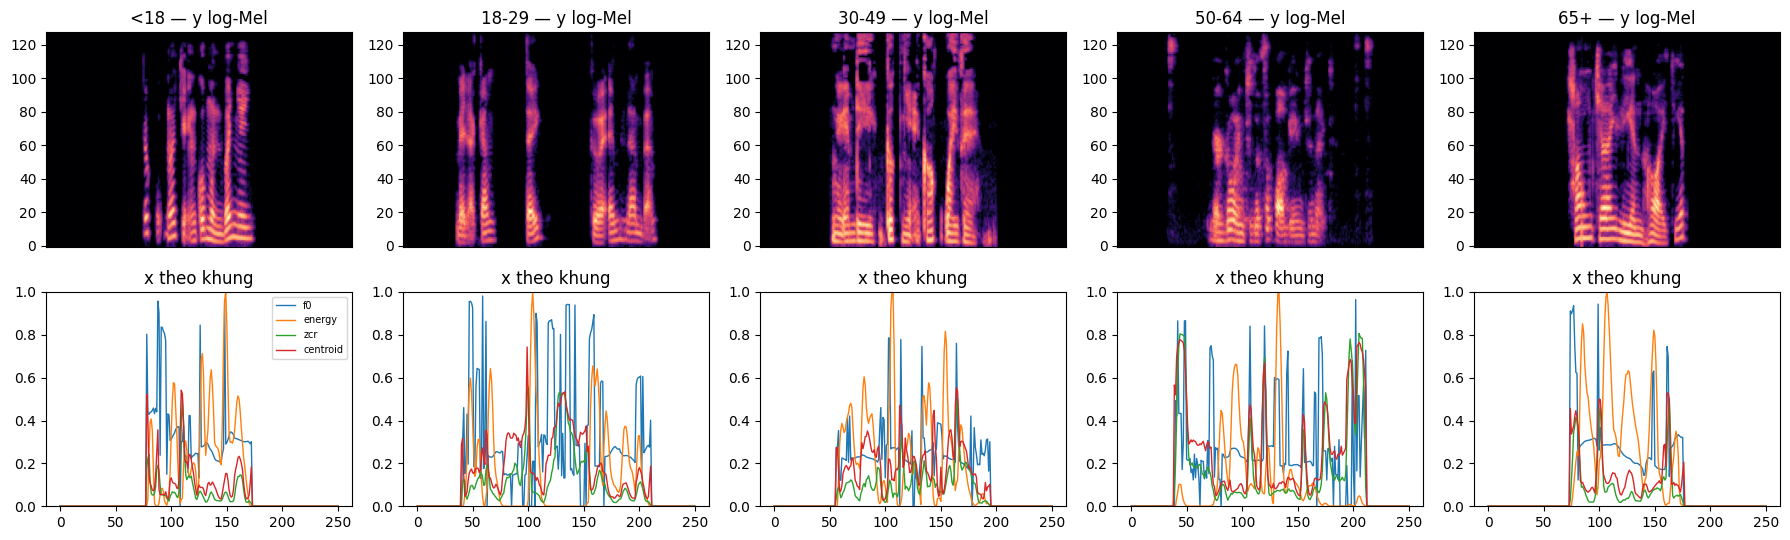

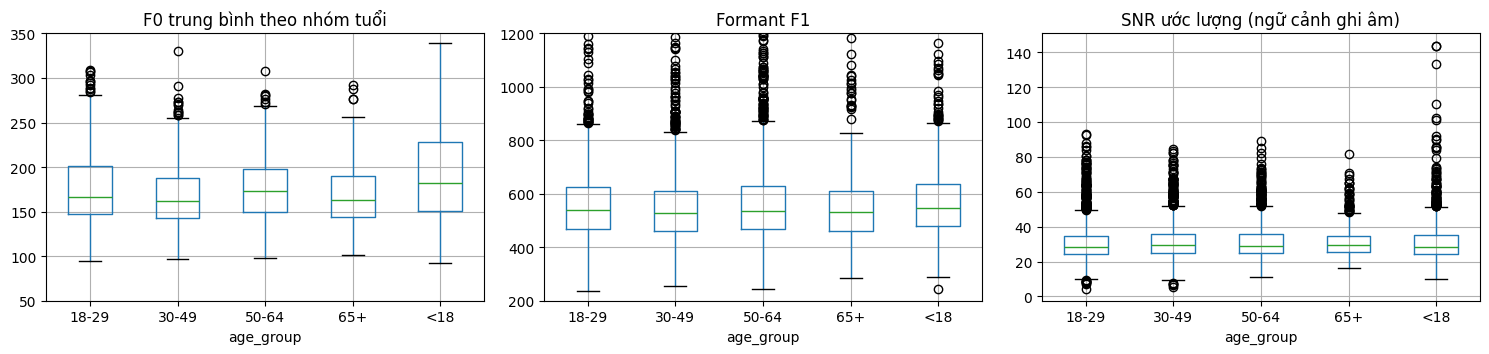

In [9]:
manifest = json.loads((INPUT / 'dataset_manifest.json').read_text(encoding='utf-8'))
print(json.dumps({k: manifest[k] for k in ['n_clips', 'n_speakers', 'label_counts', 'split_counts', 'sources', 'split_strategy']}, indent=1, ensure_ascii=False))
mel = np.load(INPUT / 'mel_logspec.npy', mmap_mode='r'); exog = np.load(INPUT / 'exog_series.npy', mmap_mode='r'); scal = pd.read_csv(INPUT / 'features_scalar.csv')
print('mel_logspec.npy', mel.shape, mel.dtype, '| exog_series.npy', exog.shape, exog.dtype, '| features_scalar.csv', scal.shape)
assert len(meta) == mel.shape[0] == exog.shape[0] == len(scal)

fig, axes = plt.subplots(2, 5, figsize=(18, 5.5))
for j, g in enumerate(AGE_GROUPS):
    i = meta.index[(meta.age_group == g) & (meta.split == 'train')][0]
    axes[0, j].imshow(np.asarray(mel[i], dtype=np.float32), origin='lower', aspect='auto', cmap='magma'); axes[0, j].set_title(f'{g} — y log-Mel'); axes[0, j].set_xticks([])
    e = np.asarray(exog[i], dtype=np.float32)
    for c in EXOG_FRAME_COLS: axes[1, j].plot(e[EXOG_COLS.index(c)], lw=1, label=c.replace('_contour', ''))
    axes[1, j].set_title('x theo khung'); axes[1, j].set_ylim(0, 1)
axes[1, 0].legend(fontsize=7); plt.tight_layout(); plt.show()

df = meta.merge(scal, on='clip_id')
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
df.boxplot(column='f0_mean', by='age_group', ax=ax[0]); ax[0].set_title('F0 trung bình theo nhóm tuổi'); ax[0].set_ylim(50, 350)
df.boxplot(column='formant_f1', by='age_group', ax=ax[1]); ax[1].set_title('Formant F1'); ax[1].set_ylim(200, 1200)
df.boxplot(column='snr_db', by='age_group', ax=ax[2]); ax[2].set_title('SNR ước lượng (ngữ cảnh ghi âm)')
plt.suptitle(''); plt.tight_layout(); plt.show()

## 5. Chạy lại pipeline trên một tập nhỏ ngay trong notebook (demo "từ thô đến dataset")

Để thấy toàn bộ bước 2–4 nối liền nhau, ta lấy 40 clip từ `raw_manifest`/audio trong dataset, xử lý bằng `process_clip`, chia theo speaker và ghi ra `/kaggle/working/mini_dataset/`
— đúng cấu trúc mà `scripts/03_build_dataset.py` tạo ra.

In [10]:
mini_dir = WORK / 'mini_dataset'; mini_dir.mkdir(exist_ok=True)
sub = pd.concat([d.sample(min(8, len(d)), random_state=0) for _, d in meta.groupby('age_group')]).reset_index(drop=True)
mels, exogs, rows = [], [], []
for _, r in sub.iterrows():
    _, F = ap.process_clip(str(INPUT / 'audio_16k_flac' / f'{r.clip_id}.flac'), recorded_at=None, source_mic=False)
    mels.append(F.log_mel); exogs.append(F.exog); rows.append({'clip_id': r.clip_id, 'speaker_id': r.speaker_id, 'age_group': r.age_group, 'locale': r.locale, **F.scalars})
mini = pd.DataFrame(rows); mini['split'] = build_ds.speaker_split(mini, 0.15, 0.15, 42).values; mini['label'] = mini.age_group.map({g: i for i, g in enumerate(AGE_GROUPS)})
np.save(mini_dir / 'mel_logspec.npy', np.stack(mels)); np.save(mini_dir / 'exog_series.npy', np.stack(exogs)); mini.to_csv(mini_dir / 'metadata_features.csv', index=False)
print('Đã ghi', sorted(p.name for p in mini_dir.iterdir()), '| mel', np.stack(mels).shape, '| exog', np.stack(exogs).shape)
display(mini[['clip_id', 'speaker_id', 'age_group', 'split', 'f0_mean', 'formant_f1', 'snr_db', 'speech_duration_s']].head(10))

Đã ghi ['exog_series.npy', 'mel_logspec.npy', 'metadata_features.csv'] | mel (40, 128, 251) | exog (40, 13, 251)


,clip_id,speaker_id,age_group,split,f0_mean,formant_f1,snr_db,speech_duration_s
0,cvvi_common_voice_vi_32079995,465263460880a414444176f5,18-29,train,152.376770,712.797180,36.665222,3.712
1,cven_common_voice_en_20434001,25cb7b733f8acf80c828d6e9,18-29,train,185.356308,568.425537,35.683868,5.000
2,cvvi_common_voice_vi_22028463,353f059e70df6baec9e748ef,18-29,val,221.916122,669.429260,28.318279,1.888
3,cvvi_common_voice_vi_36605376,0a1a28f013c5863c9036144f,18-29,test,195.979736,457.812744,34.970352,1.088
4,cven_common_voice_en_21234,4bd9ad759e9ab7ca65668cd8,18-29,train,130.465256,496.919220,65.272079,1.984
5,cvvi_common_voice_vi_29405238,f322c73948705a9ea6ba9fc0,18-29,train,229.286469,401.399719,23.752434,1.568
6,cvvi_common_voice_vi_28565099,8e0630cf30b0130abf816cde,18-29,train,134.736877,604.422729,28.280668,2.944
7,cvvi_common_voice_vi_25721863,b5b9218efb4e1cbe9ecb3b71,18-29,train,214.624786,488.803864,28.937855,2.496
8,cven_common_voice_en_189237,c8cd20d060f39c2eb6e74f88,30-49,test,156.303925,538.142029,28.339674,1.280
9,cven_common_voice_en_25051241,2628f4b8cf28a0371d469bee,30-49,train,144.259430,525.164429,29.250275,5.000


## 6. Dữ liệu này đi vào mô hình như thế nào

* **y (log‑Mel)** → ảnh 224×224 → **DINOv3 ViT‑S/16** (thay khối Endogenous Embedding của TimeXer) → 14 token thời gian + CLS làm *global token*.
* **prosody** (51 thống kê) → Linear → 1 token nội sinh bổ sung.
* **x (13 kênh)** → `ExEmbedding` của TimeXer (giữ nguyên) → 13 *variate token* → cross‑attention với global token.
* Head phân loại 5 nhóm tuổi. Kết quả test (speaker‑disjoint): TimeXer gốc 30.0% acc / F1 0.251 → **TimeXer‑DINOv3 + prosody 39.0% / 0.335**.

Code mô hình, huấn luyện và app triển khai (FastAPI + UI ghi âm/tải file, trang `/collect` để tiếp tục thu dữ liệu private): GitHub repo
**`timexer-dinov3-voice-age`** (thư mục `src/models/`, `app/`). Dataset này là đầu ra của `scripts/06_package_kaggle.py` trong repo đó.

## 7. Tái lập pipeline đầy đủ trên máy của bạn
```bash
git clone <github-repo> && cd timexer-dinov3-voice-age && pip install -r requirements.txt
python scripts/01_seed_common_voice.py          # thu thập seed Common Voice (vi + en)
python scripts/02_ingest_private.py             # hợp nhất bản ghi private từ app /collect
python scripts/03_build_dataset.py --save-wav   # tiền xử lý + đặc trưng + split theo speaker
python scripts/06_package_kaggle.py --with-audio --username <kaggle_username>   # -> dataset này
```
